# Semana 6 — Sinapsis y sistemas lineales

**Objetivo:** ver una sinapsis como un filtro lineal de primer orden y relacionar su constante
temporal con la integración (suma temporal) de spikes de entrada.

## Modelo

Cada spike presináptico en $t_j$ incrementa la variable sináptica $s$ en 1, que luego decae:

$$\tau_s \frac{ds}{dt} = -s + \tau_s \sum_j \delta(t - t_j)$$

La respuesta a un solo spike (respuesta al impulso) es $h(t) = e^{-t/\tau_s}$ para $t \ge 0$, y la
respuesta a un tren es la convolución $s(t) = \sum_j h(t - t_j)$. Se integra de forma exacta:

$$s_{k+1} = s_k\, e^{-\Delta t/\tau_s} + (\text{número de spikes en el paso } k+1)$$

**Suma temporal:** si los spikes llegan separados menos que $\tau_s$, la respuesta no alcanza a
decaer y se acumula. Se comparan $\tau_s = 2$ ms (rápida, tipo AMPA) y $\tau_s = 10$ ms (lenta).

Entrada: una ráfaga de 4 spikes cada 3 ms (10–19 ms) y dos spikes aislados (50 y 80 ms).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from computational_neuroscience.outputs import save_data, save_figure

WEEK = 6
DT_MS = 0.1
time = np.arange(0.0, 100.0 + DT_MS / 2, DT_MS)
spike_times = np.array([10.0, 13.0, 16.0, 19.0, 50.0, 80.0])
spike_train = np.zeros(time.size)
spike_train[np.round(spike_times / DT_MS).astype(int)] = 1.0


def synaptic_response(tau_ms: float) -> np.ndarray:
    decay = np.exp(-DT_MS / tau_ms)
    response = np.zeros(time.size)
    response[0] = spike_train[0]
    for index in range(time.size - 1):
        response[index + 1] = response[index] * decay + spike_train[index + 1]
    return response


responses = {tau: synaptic_response(tau) for tau in (2.0, 10.0)}

## Figura

Arriba: los spikes de entrada. Abajo: la variable sináptica para cada $\tau_s$. Con
$\tau_s = 10$ ms la ráfaga se suma hasta superar 2; con $\tau_s = 2$ ms cada spike casi
desaparece antes del siguiente.

Saved: weeks/week_06_synaptic_filter/outputs/synaptic_filter.png
Saved: weeks/week_06_synaptic_filter/outputs/synaptic_filter.npz


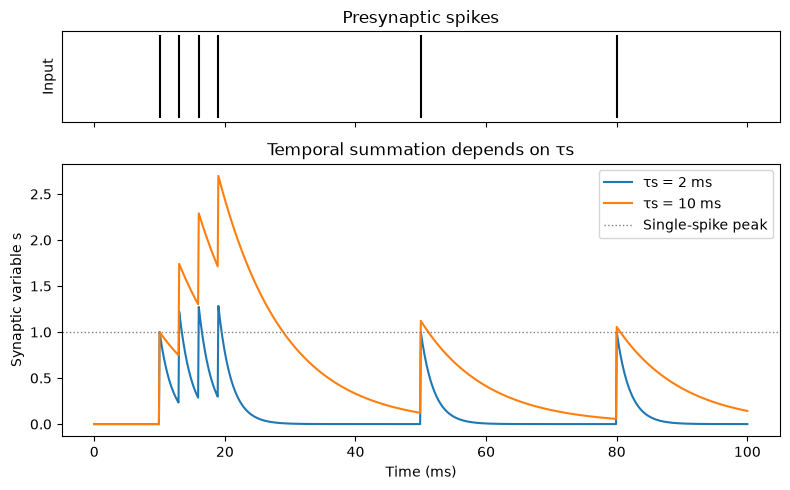

In [2]:
figure, axes = plt.subplots(2, 1, figsize=(8, 5), sharex=True, gridspec_kw={"height_ratios": [1, 3]})
axes[0].vlines(spike_times, 0, 1, color="black")
axes[0].set(ylabel="Input", yticks=[], title="Presynaptic spikes")
for tau, response in responses.items():
    axes[1].plot(time, response, label=f"τs = {tau:g} ms")
axes[1].axhline(1.0, color="grey", linestyle=":", linewidth=1, label="Single-spike peak")
axes[1].set(xlabel="Time (ms)", ylabel="Synaptic variable s", title="Temporal summation depends on τs")
axes[1].legend()
save_figure(WEEK, figure, "synaptic_filter.png")
save_data(WEEK, "synaptic_filter.npz", time_ms=time, spike_times_ms=spike_times,
          **{f"response_tau_{tau:g}": response for tau, response in responses.items()})

## Validación

- Tras un spike aislado, $s$ cae a $e^{-1} \approx 0.368$ después de un $\tau_s$.
- La respuesta es la suma de respuestas al impulso (linealidad): coincide con la convolución.
- Durante la ráfaga, el pico con $\tau_s = 10$ ms supera 2; con $\tau_s = 2$ ms queda por debajo de 1.5.

In [3]:
for tau, response in responses.items():
    start = int(round(50.0 / DT_MS))
    after_tau = response[start + int(round(tau / DT_MS))] - response[start - 1] * np.exp(-(tau + DT_MS) / tau)
    assert abs(after_tau - np.exp(-1.0)) < 0.01, (tau, after_tau)
    kernel = np.exp(-time / tau)
    assert np.allclose(response, np.convolve(spike_train, kernel)[: time.size])
burst = time < 30.0
assert responses[10.0][burst].max() > 2.0
assert responses[2.0][burst].max() < 1.5
print({f"tau={tau:g} ms": f"burst peak {response[burst].max():.2f}" for tau, response in responses.items()})

{'tau=2 ms': 'burst peak 1.28', 'tau=10 ms': 'burst peak 2.70'}


## Interpretación y límites

- Una constante temporal larga integra entradas cercanas en el tiempo (suma temporal);
  una corta detecta coincidencias precisas.
- Es un modelo lineal: no incluye saturación de receptores, depresión ni facilitación sináptica.

**Para tu entrega:** ¿qué intervalo entre spikes hace que el pico con $\tau_s = 10$ ms llegue a
1.5? Predícelo con $1 + e^{-\Delta/\tau_s}$ y compruébalo.